# MovieLens 100K: user–movie matrix and movie distributions

This notebook reads **`u.item`** and **`u.data`** from `RecSys-LLMs/week3`. The full user–movie matrix remains available as `rating_matrix`. Its rows are user IDs, columns are movie IDs, values are ratings from 1 to 5, and `NaN` means the user did not rate the movie. The notebook displays a small labeled slice and a map of all observed ratings, then explores movie popularity, genres, and rating values.

Run all cells in order. The path resolver supports launching Jupyter from either the repository root or `llm-4-res-sys/week3`.

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "seaborn-whitegrid")

candidates = [Path("./")]
data_dir = next((path for path in candidates if (path / "u.item").is_file() and (path / "u.data").is_file()), None)
if data_dir is None:
    raise FileNotFoundError("Could not find RecSys-LLMs/week3/{u.item,u.data}; run from the repository root or llm-4-res-sys/week3")

rating_columns = ["user_id", "item_id", "rating", "timestamp"]
genres = ["unknown", "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]
item_columns = ["item_id", "title", "release_date", "video_release_date", "imdb_url"] + genres

ratings = pd.read_csv(data_dir / "u.data", sep="\t", header=None, names=rating_columns)
items = pd.read_csv(data_dir / "u.item", sep="|", header=None, names=item_columns, encoding="latin-1")
print(f"Data directory: {data_dir.resolve()}")
print(f"Ratings: {len(ratings):,}; catalog movies: {len(items):,}")

Data directory: /Users/raimova-al/Documents/study/master/res_sys/llm-4-res-sys/week3
Ratings: 100,000; catalog movies: 1,682


## Data checks

Each `(user_id, item_id)` pair should occur once, all ratings should be from 1 to 5, and every rated movie should exist in `u.item`.

In [18]:
assert items.item_id.is_unique, "Duplicate movie IDs in u.item"
assert not ratings.duplicated(["user_id", "item_id"]).any(), "Duplicate user–movie ratings"
assert ratings.rating.between(1, 5).all(), "Unexpected rating value"
assert ratings.item_id.isin(items.item_id).all(), "Rating refers to a movie absent from u.item"
assert not ratings[["user_id", "item_id", "rating"]].isna().any().any()

summary = pd.Series({
    "ratings": len(ratings),
    "users": ratings.user_id.nunique(),
    "movies in catalog": items.item_id.nunique(),
    "movies with ratings": ratings.item_id.nunique(),
    "minimum rating": ratings.rating.min(),
    "maximum rating": ratings.rating.max(),
}, name="value")
display(summary.to_frame())

,value
ratings,100000
users,943
movies in catalog,1682
movies with ratings,1682
minimum rating,1
maximum rating,5


## User–movie matrix

`rating_matrix` contains every user and every catalog movie. Missing entries stay `NaN` so they cannot be confused with a real rating. The table below shows the first 12 users and movies; use `rating_matrix` to inspect any other slice. The heatmap shows the complete matrix: a colored pixel means an observed rating.

In [19]:
user_ids = np.sort(ratings.user_id.unique())
movie_ids = np.sort(items.item_id.unique())
rating_matrix = (ratings.pivot(index="user_id", columns="item_id", values="rating")
                 .reindex(index=user_ids, columns=movie_ids))
rating_matrix.index.name = "user_id"
rating_matrix.columns.name = "item_id"
assert rating_matrix.shape == (ratings.user_id.nunique(), items.item_id.nunique())
assert int(rating_matrix.notna().sum().sum()) == len(ratings)

title_by_id = items.set_index("item_id").title
matrix_slice = rating_matrix.iloc[:12, :12].rename(columns=lambda item_id: f"{item_id}: {title_by_id.loc[item_id]}")
print(f"Full matrix: {rating_matrix.shape[0]} users × {rating_matrix.shape[1]} movies")
print(f"Observed cells: {rating_matrix.notna().sum().sum():,} / {rating_matrix.size:,} ({rating_matrix.notna().to_numpy().mean():.2%})")
display(matrix_slice)

Full matrix: 943 users × 1682 movies
Observed cells: 100,000 / 1,586,126 (6.30%)


item_id,1: Toy Story (1995),2: GoldenEye (1995),3: Four Rooms (1995),4: Get Shorty (1995),5: Copycat (1995),6: Shanghai Triad (Yao a yao yao dao waipo qiao) (1995),7: Twelve Monkeys (1995),8: Babe (1995),9: Dead Man Walking (1995),10: Richard III (1995),11: Seven (Se7en) (1995),"12: Usual Suspects, The (1995)"
user_id,,,,,,,,,,,,
1,5.0,3.0,4.0,3.0,3.0,5.0,4.0,1.0,5.0,3.0,2.0,5.0
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,NaN
5,4.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,4.0,NaN,NaN,NaN,NaN,NaN,2.0,4.0,4.0,NaN,NaN,4.0
7,NaN,NaN,NaN,5.0,NaN,NaN,5.0,5.0,5.0,4.0,3.0,5.0
8,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,3.0,NaN
9,NaN,NaN,NaN,NaN,NaN,5.0,4.0,NaN,NaN,NaN,NaN,NaN


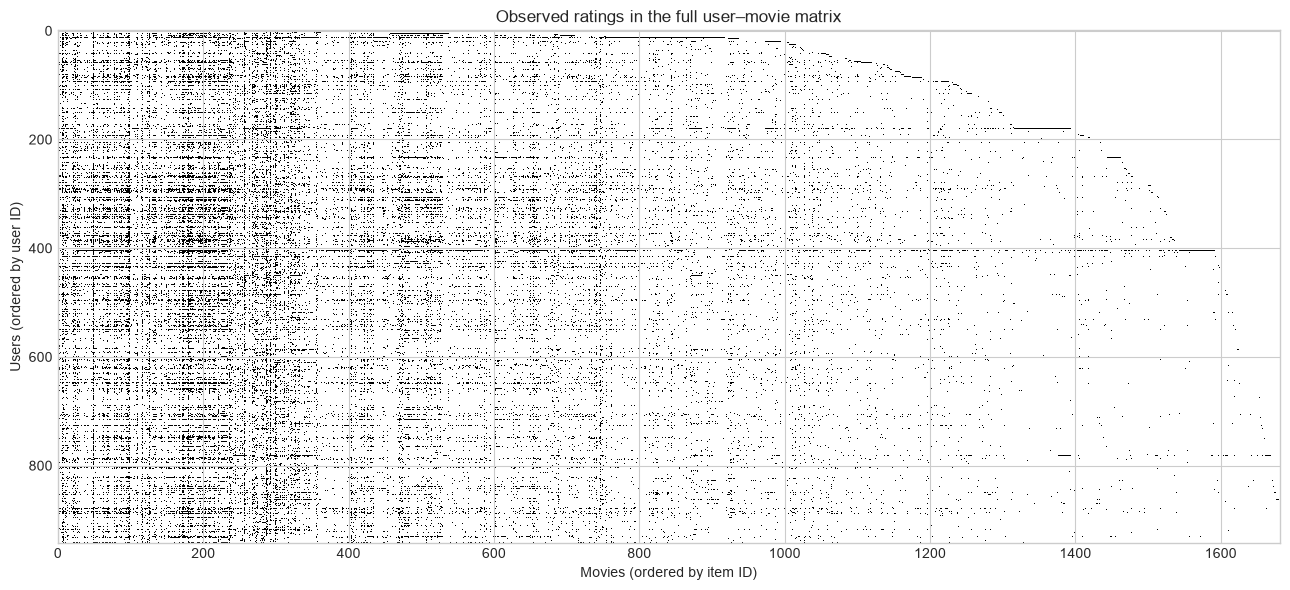

In [20]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(rating_matrix.notna().to_numpy(), aspect="auto", interpolation="nearest", cmap="Greys")
ax.set(title="Observed ratings in the full user–movie matrix", xlabel="Movies (ordered by item ID)", ylabel="Users (ordered by user ID)")
plt.tight_layout()
plt.show()

## Distribution of movies by number of ratings

A movie's **popularity** here is the number of ratings it received. The histogram includes every catalog movie, including movies with zero ratings if any exist. The table and chart show the 15 most rated titles.

In [21]:
rating_counts = ratings.groupby("item_id").size().rename("rating_count")
movie_popularity = (items[["item_id", "title"]]
                    .merge(rating_counts, left_on="item_id", right_index=True, how="left")
                    .fillna({"rating_count": 0}))
movie_popularity["rating_count"] = movie_popularity.rating_count.astype(int)
movie_popularity = movie_popularity.sort_values(["rating_count", "item_id"], ascending=[False, True])
assert movie_popularity.rating_count.sum() == len(ratings)

print("Ratings per movie:")
display(movie_popularity.rating_count.describe(percentiles=[.10, .25, .50, .75, .90, .95, .99]).to_frame())
print("Most rated movies:")
display(movie_popularity.head(15).reset_index(drop=True))

Ratings per movie:


,rating_count
count,1682.000000
mean,59.453032
std,80.383846
min,1.000000
10%,2.000000
25%,6.000000
50%,27.000000
75%,80.000000
90%,169.000000
95%,229.850000


Most rated movies:


,item_id,title,rating_count
0,50,Star Wars (1977),583
1,258,Contact (1997),509
2,100,Fargo (1996),508
3,181,Return of the Jedi (1983),507
4,294,Liar Liar (1997),485
5,286,"English Patient, The (1996)",481
6,288,Scream (1996),478
7,1,Toy Story (1995),452
8,300,Air Force One (1997),431
9,121,Independence Day (ID4) (1996),429


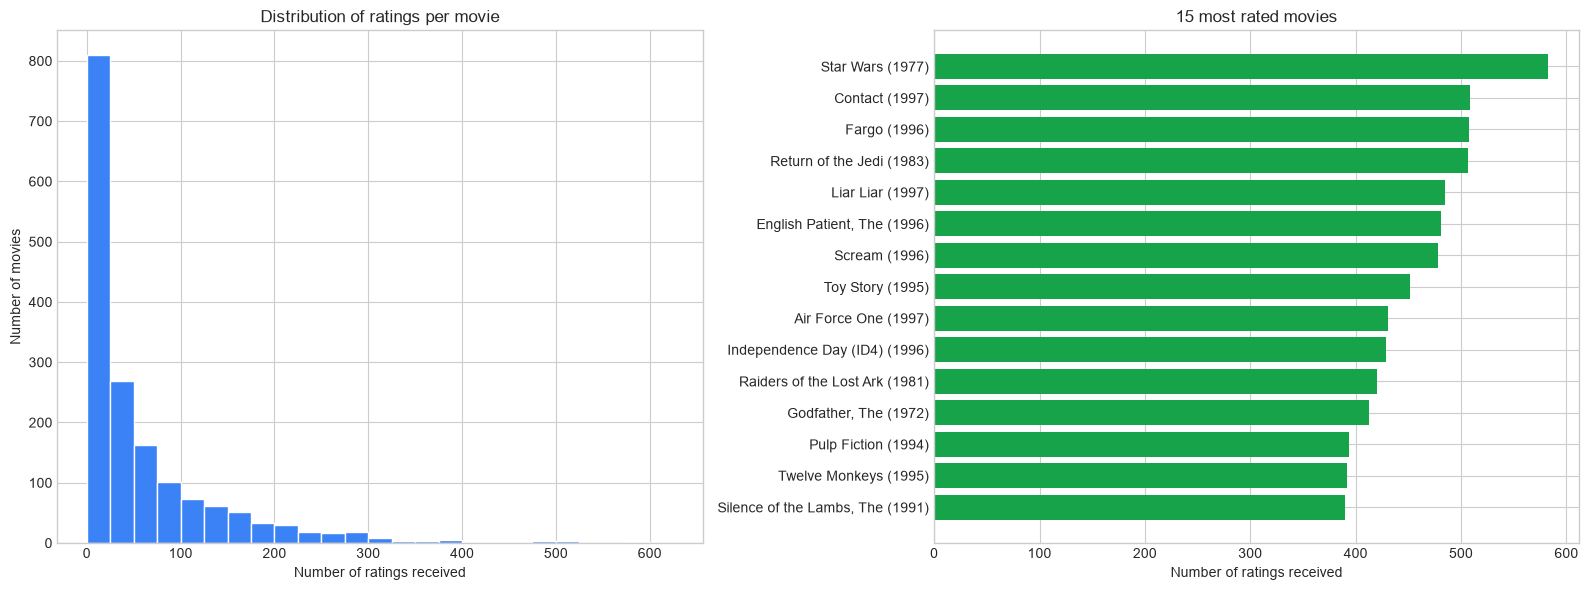

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bin_width = 25
bins = np.arange(0, movie_popularity.rating_count.max() + 2 * bin_width, bin_width)
axes[0].hist(movie_popularity.rating_count, bins=bins, color="#3b82f6", edgecolor="white")
axes[0].set(title="Distribution of ratings per movie", xlabel="Number of ratings received", ylabel="Number of movies")

top_movies = movie_popularity.head(15).iloc[::-1]
axes[1].barh(top_movies.title, top_movies.rating_count, color="#16a34a")
axes[1].set(title="15 most rated movies", xlabel="Number of ratings received")
fig.tight_layout()
plt.show()

## Distribution of movies by genre

The catalog has multiple genre flags per movie. A movie may be counted in more than one genre, so the bars do not sum to the number of movies.

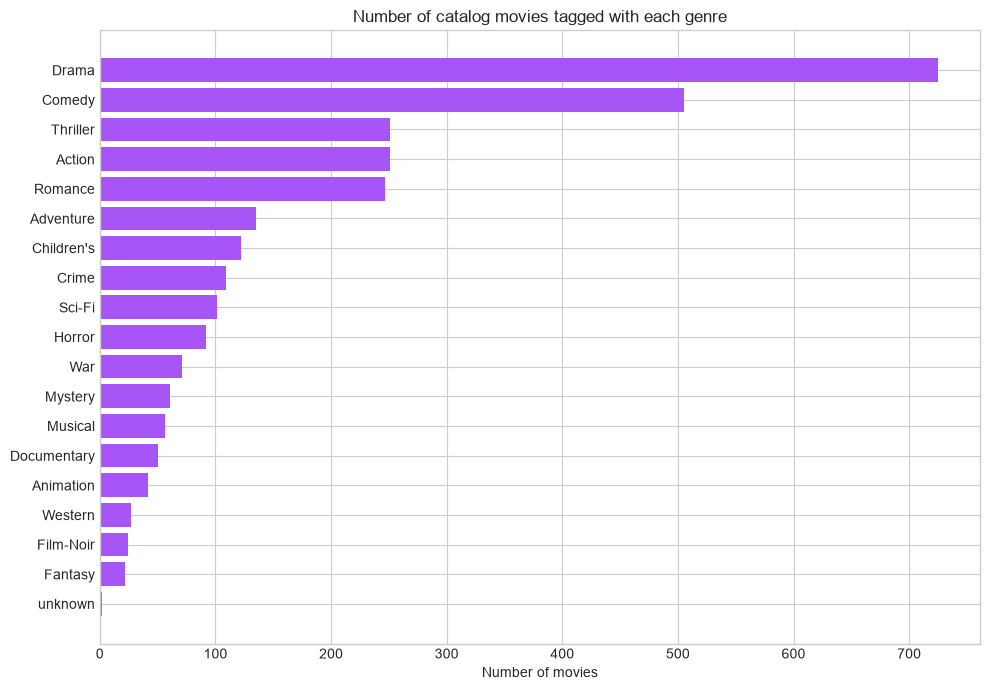

,movie_count
Drama,725
Comedy,505
Thriller,251
Action,251
Romance,247
Adventure,135
Children's,122
Crime,109
Sci-Fi,101
Horror,92


In [23]:
genre_counts = items[genres].sum().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(genre_counts.index, genre_counts.values, color="#a855f7")
ax.set(title="Number of catalog movies tagged with each genre", xlabel="Number of movies")
plt.tight_layout()
plt.show()
display(genre_counts.sort_values(ascending=False).rename("movie_count").to_frame())

## Distribution of rating values

This chart describes the 100,000 rating events rather than the movies themselves. It helps distinguish movie popularity from the score distribution.

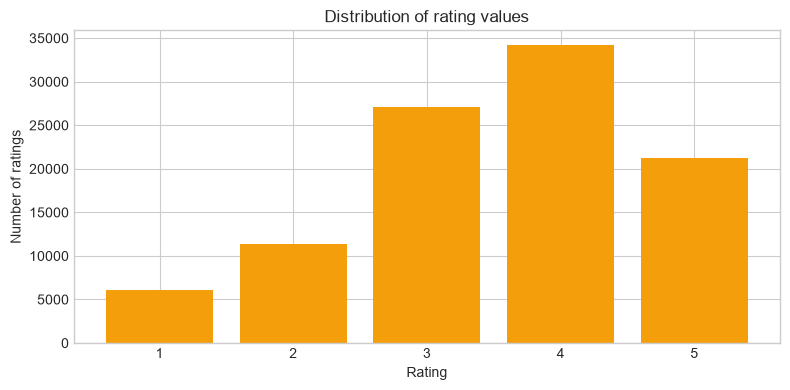

,count
rating,
1,6110
2,11370
3,27145
4,34174
5,21201


In [24]:
rating_value_counts = ratings.rating.value_counts().sort_index().reindex(range(1, 6), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(rating_value_counts.index, rating_value_counts.values, color="#f59e0b")
ax.set(title="Distribution of rating values", xlabel="Rating", ylabel="Number of ratings", xticks=range(1, 6))
plt.tight_layout()
plt.show()
display(rating_value_counts.rename("count").to_frame())

In [25]:
print(f"Median movie popularity: {movie_popularity.rating_count.median():.0f} ratings")
print(f"Most rated movie: {movie_popularity.iloc[0].title} ({movie_popularity.iloc[0].rating_count} ratings)")
print(f"Matrix sparsity: {1 - rating_matrix.notna().to_numpy().mean():.2%} missing entries")

Median movie popularity: 27 ratings
Most rated movie: Star Wars (1977) (583 ratings)
Matrix sparsity: 93.70% missing entries


## Cold-start users and movies

**Strict cold start** means zero recorded ratings for a user or a catalog movie. A missing cell in the user–movie matrix is not enough: that user and movie may each have many ratings elsewhere. `u.data` does not enumerate entirely new users, so the user count below covers IDs from 1 through the largest observed user ID. The movie count covers all movies listed in `u.item`.

The dataset has no strict cold-start examples. To show practical **few-rating cases**, the next cell separately counts users with 1–20 ratings and movies with 1–5 ratings. These thresholds are chosen for exploration; few-rating cases are not the same as zero-rating cold start.

In [26]:
known_user_ids = pd.Index(range(1, int(ratings.user_id.max()) + 1), name="user_id")
catalog_movie_ids = pd.Index(items.item_id, name="item_id")
user_rating_counts = ratings.groupby("user_id").size().reindex(known_user_ids, fill_value=0)
movie_rating_counts = ratings.groupby("item_id").size().reindex(catalog_movie_ids, fill_value=0)

cold_users = user_rating_counts[user_rating_counts.eq(0)]
cold_movies = movie_rating_counts[movie_rating_counts.eq(0)]
print(f"Strict cold-start users (0 ratings): {len(cold_users)}")
print("User examples:", cold_users.index[:10].tolist() if len(cold_users) else "none in the known ID range")
print(f"Strict cold-start movies (0 ratings): {len(cold_movies)}")
if len(cold_movies):
    print(items.loc[items.item_id.isin(cold_movies.index), ["item_id", "title"]].head(10).to_string(index=False))
else:
    print("Movie examples: none in the catalog")

Strict cold-start users (0 ratings): 0
User examples: none in the known ID range
Strict cold-start movies (0 ratings): 0
Movie examples: none in the catalog


In [27]:
few_user_limit = 20
few_movie_limit = 5
few_users = (user_rating_counts[user_rating_counts.between(1, few_user_limit)]
             .rename("rating_count").rename_axis("user_id").reset_index()
             .sort_values(["rating_count", "user_id"]))
few_movies = (movie_rating_counts[movie_rating_counts.between(1, few_movie_limit)]
              .rename("rating_count").rename_axis("item_id").reset_index()
              .merge(items[["item_id", "title"]], on="item_id", how="left")
              .sort_values(["rating_count", "item_id"]))
print(f"Users with 1–{few_user_limit} ratings: {len(few_users)}")
print("Examples of users with few ratings:")
print(few_users.head(10).to_string(index=False))
print(f"\nMovies with 1–{few_movie_limit} ratings: {len(few_movies)}")
print("Examples of movies with few ratings:")
print(few_movies.head(10)[["item_id", "title", "rating_count"]].to_string(index=False))

Users with 1–20 ratings: 32
Examples of users with few ratings:
 user_id  rating_count
      19            20
      34            20
      36            20
      93            20
     143            20
     147            20
     166            20
     202            20
     242            20
     300            20

Movies with 1–5 ratings: 384
Examples of movies with few ratings:
 item_id                                             title  rating_count
     599 Police Story 4: Project S (Chao ji ji hua) (1993)             1
     677                       Fire on the Mountain (1996)             1
     711                     Substance of Fire, The (1996)             1
     814                     Great Day in Harlem, A (1994)             1
     830                                   Power 98 (1995)             1
     852                          Bloody Child, The (1996)             1
     857                          Paris Was a Woman (1995)             1
    1122                    They

## Reproducible collaborative-filtering experiment

This section evaluates **three user-based CF similarity methods** and a separate **matrix-factorization benchmark** on the same MovieLens ratings. All methods use the same catalog, users, and held-out pairs. For each user, ratings are ordered by `(timestamp, item_id)`; the earliest 70% train the models, the next 15% form validation, and the rest form the held-out test set. Item ID breaks equal-timestamp ties deterministically. We do **not** refit on validation after tuning, so every final model uses only the original train partition.

The implementation is in `evaluation.py`; focused checks are in `test_evaluation.py`. Numeric outputs below are produced by running the code, not entered by hand.

**Development disclosure:** Preliminary test diagnostics were inspected while building this notebook. No test ratings enter model fitting or hyperparameter selection, which uses validation RMSE only, but the reported test set was not completely unseen during development.

In [28]:
import platform
import subprocess
import sys

experiment_dir = next((folder for folder in [Path.cwd(), Path("llm-4-res-sys/week3")]
                       if (folder / "evaluation.py").is_file()), None)
if experiment_dir is None:
    raise FileNotFoundError("Run from the repository root or llm-4-res-sys/week3")
if str(experiment_dir.resolve()) not in sys.path:
    sys.path.insert(0, str(experiment_dir.resolve()))
import evaluation as ev

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

train_ratings, validation_ratings, test_ratings = ev.chronological_split(ratings)
train_data = ev.build_training_data(train_ratings, ratings.user_id.unique(), items.item_id)
train_pairs = set(zip(train_ratings.user_id, train_ratings.item_id))
validation_pairs = set(zip(validation_ratings.user_id, validation_ratings.item_id))
test_pairs = set(zip(test_ratings.user_id, test_ratings.item_id))
assert train_pairs.isdisjoint(validation_pairs)
assert train_pairs.isdisjoint(test_pairs)
assert validation_pairs.isdisjoint(test_pairs)
assert len(train_ratings) + len(validation_ratings) + len(test_ratings) == len(ratings)

print(f"Python {platform.python_version()}, NumPy {np.__version__}, pandas {pd.__version__}")
print(f"Train: {len(train_ratings):,}; validation: {len(validation_ratings):,}; test: {len(test_ratings):,}")
print(f"Users: {len(train_data.user_ids):,}; catalog movies: {len(train_data.item_ids):,}")
print(f"Relevant validation ratings (>=4): {(validation_ratings.rating >= 4).sum():,}")
print(f"Relevant test ratings (>=4): {(test_ratings.rating >= 4).sum():,}")
print("Split overlap checks passed; every method will use these same partitions.")

Python 3.13.7, NumPy 2.3.2, pandas 2.3.1
Train: 69,572; validation: 14,577; test: 15,851
Users: 943; catalog movies: 1,682
Relevant validation ratings (>=4): 7,201
Relevant test ratings (>=4): 7,599
Split overlap checks passed; every method will use these same partitions.


### Prediction and ranking protocol

All three neighborhood methods use **cosine similarity**, select the same number *K* of positive-similarity neighbors, and predict an unseen rating as

`sum(similarity(user, neighbor) × neighbor's observed rating) / sum(similarity(user, neighbor))`,

where the sums include only selected neighbors who actually rated that candidate. Mean-imputed values affect user similarity only: they are never treated as observed neighbor ratings or as items the target user consumed. Matrix factorization scores candidates directly as a separate benchmark. If no selected neighbor rated the candidate, the fallback is its **train item mean**; if that item has no train ratings, it is the **train user mean** (or train global mean for a new user). A pair with no common ratings has similarity zero. The default accepts even one common rating; common-rating weighting shrinks cosine by `min(n_common / 50, 1)`.

The factorization benchmark predicts `global mean + user bias + item bias + user factors · item factors`, trained with regularization on **observed train ratings only**. It uses the same train-derived fallback for users or items with no train history.

MAE and RMSE use identical held-out rating pairs. For ranking, every method scores the **same full catalog minus each user's train-rated items** and returns Top 5. A test rating of at least 4 is relevant. Recall@5 and NDCG@5 average over test users with at least one relevant test item. Recall divides Top-5 hits by **all** relevant test items; binary NDCG discounts hits by rank and divides by the ideal DCG at five. Validation-rated movies remain candidates in this frozen train-only user profile, but they are not test positives. Missing test labels are *unknown*, not dislikes; a good unlabelled recommendation receives no credit, so these sparse-label ranking metrics are limited.

**Prediction coverage** is the fraction of test ratings scored with neighbor evidence (or trained factors), before fallback. **Recommendation coverage** is the fraction of catalog movies appearing in at least one user's Top 5. Runtime includes fitting, full-catalog scoring, and metrics; it excludes loading data and hyperparameter search. These are single warm-process timings and will vary by machine.

The browser demo uses a different weighting formula and treats factorization as a similarity fill. This notebook follows the four experimental definitions above; its results should not be read as measurements of the browser demo.

### Validation-only tuning

Choose one shared neighbor count for the three CF methods by the **mean validation RMSE** across them. This keeps their neighbor count identical in the final comparison. The common-rating threshold is fixed at the requested value 50 but is a configurable function argument. Factor rank and regularization are selected separately by validation RMSE. Ranking metrics are reported on test rather than used to tune these settings.

In [29]:
common_threshold = 50
neighbor_grid = [10, 20, 40]
validation_rows = []
validation_similarity = {method: ev.user_similarity(train_data, method, common_threshold)
                         for method in ev.NEIGHBOR_METHODS}
for neighbor_count in neighbor_grid:
    for method in ev.NEIGHBOR_METHODS:
        candidate_scores, native = ev.score_neighborhood(
            train_data, validation_similarity[method], neighbor_count
        )
        measures = ev.rating_metrics(train_data, candidate_scores, native, validation_ratings)
        validation_rows.append({"neighbors": neighbor_count, "method": method,
                                "validation_MAE": measures["MAE"],
                                "validation_RMSE": measures["RMSE"]})
validation_cf = pd.DataFrame(validation_rows)
shared_neighbor_count = int(validation_cf.groupby("neighbors").validation_RMSE.mean().idxmin())
print("Shared neighbors chosen on validation:", shared_neighbor_count)
display(validation_cf.round(4))
display(validation_cf.groupby("neighbors").validation_RMSE.mean()
        .rename("mean_validation_RMSE").round(4).to_frame())

Shared neighbors chosen on validation: 10


,neighbors,method,validation_MAE,validation_RMSE
0,10,co_rated,0.8746,1.1106
1,10,user_mean,0.8674,1.1072
2,10,common_weight,0.8879,1.1383
3,20,co_rated,0.8838,1.1238
4,20,user_mean,0.8875,1.1376
5,20,common_weight,0.8740,1.1135
6,40,co_rated,0.8926,1.1372
7,40,user_mean,0.9008,1.1606
8,40,common_weight,0.8560,1.0852


,mean_validation_RMSE
neighbors,
10,1.1187
20,1.1249
40,1.1277


In [30]:
factor_rows = []
factor_grid = [(rank, regularization) for rank in [8, 16]
               for regularization in [0.02, 0.10]]
for rank, regularization in factor_grid:
    config = {"rank": rank, "regularization": regularization,
              "epochs": 40, "learning_rate": 0.15, "seed": 42}
    model = ev.fit_factor_model(train_data, **config)
    candidate_scores, native = ev.score_factor_model(train_data, model)
    measures = ev.rating_metrics(train_data, candidate_scores, native, validation_ratings)
    factor_rows.append({"rank": rank, "regularization": regularization,
                        "validation_MAE": measures["MAE"],
                        "validation_RMSE": measures["RMSE"]})
validation_factor = pd.DataFrame(factor_rows).sort_values(
    ["validation_RMSE", "rank", "regularization"]
).reset_index(drop=True)
selected_factor_config = {"rank": int(validation_factor.iloc[0]["rank"]),
                          "regularization": float(validation_factor.iloc[0]["regularization"]),
                          "epochs": 40, "learning_rate": 0.15, "seed": 42}
print("Selected matrix-factorization settings:", selected_factor_config)
display(validation_factor.round(4))

Selected matrix-factorization settings: {'rank': 8, 'regularization': 0.02, 'epochs': 40, 'learning_rate': 0.15, 'seed': 42}


,rank,regularization,validation_MAE,validation_RMSE
0,8,0.02,0.7704,0.9739
1,16,0.02,0.7706,0.9739
2,16,0.10,0.7736,0.9748
3,8,0.10,0.7736,0.9749


### Held-out test results

All four methods below use the same test ratings and the same eligible catalog items for each user. We fit again from the unchanged train partition using the validation-selected settings.

In [31]:
method_names = {"co_rated": "Default: co-rated",
                "user_mean": "User mean imputation",
                "common_weight": "Common-rating weighting",
                "matrix_factorization": "Matrix factorization"}
test_rows = []
history_tables = []
score_matrices = {}
ranking_details = {}
for method in [*ev.NEIGHBOR_METHODS, "matrix_factorization"]:
    measures, by_history, method_scores, method_rankings = ev.evaluate_method(
        train_data, test_ratings, method,
        neighbor_count=shared_neighbor_count,
        common_threshold=common_threshold,
        factor_config=selected_factor_config,
        return_details=True,
    )
    score_matrices[method] = method_scores
    ranking_details[method] = method_rankings
    test_rows.append({"method": method_names[method], **measures})
    history_tables.append(by_history.assign(method=method_names[method]))
test_results = pd.DataFrame(test_rows)[
    ["method", "MAE", "RMSE", "Recall@5", "NDCG@5",
     "prediction_coverage", "recommendation_coverage", "runtime_seconds", "ranking_users"]
]
print(f"Test rating pairs: {len(test_ratings):,}; Top-5 evaluated users: {int(test_results.ranking_users.iloc[0]):,}")
display(test_results.round(4))

Test rating pairs: 15,851; Top-5 evaluated users: 899


,method,MAE,RMSE,Recall@5,NDCG@5,prediction_coverage,recommendation_coverage,runtime_seconds,ranking_users
0,Default: co-rated,0.9039,1.1448,0.0062,0.0115,0.1689,0.1468,0.6900,899
1,User mean imputation,0.8991,1.1439,0.0090,0.0181,0.1832,0.1082,0.6612,899
2,Common-rating weighting,0.9152,1.1732,0.0038,0.0093,0.7644,0.1706,0.6839,899
3,Matrix factorization,0.8066,1.0141,0.0005,0.0013,0.9932,0.0268,0.9322,899


In [32]:
history_results = pd.concat(history_tables, ignore_index=True)[
    ["method", "train_history", "users", "test_ratings", "RMSE", "Recall@5", "NDCG@5"]
]
print("Groups use only each user's number of TRAIN ratings; all methods share the same groups.")
display(history_results.round(4))

Groups use only each user's number of TRAIN ratings; all methods share the same groups.


,method,train_history,users,test_ratings,RMSE,Recall@5,NDCG@5
0,Default: co-rated,1–19,187,803,1.2755,0.0042,0.0026
1,Default: co-rated,20–49,317,2523,1.1873,0.0064,0.0058
2,Default: co-rated,50–99,191,3186,1.1352,0.0105,0.0209
3,Default: co-rated,100+,248,9339,1.1242,0.0038,0.0174
4,User mean imputation,1–19,187,803,1.2914,0.0094,0.0050
5,User mean imputation,20–49,317,2523,1.1698,0.0091,0.0107
6,User mean imputation,50–99,191,3186,1.1381,0.0107,0.0217
7,User mean imputation,100+,248,9339,1.1252,0.0074,0.0332
8,Common-rating weighting,1–19,187,803,1.2437,0.0036,0.0024
9,Common-rating weighting,20–49,317,2523,1.1802,0.0027,0.0041


### Paired differences from the default

The next table compares methods on the **same individual test ratings** and the **same ranking users**. For rating error it first computes each user's MAE, then averages the within-user difference from the default; every user therefore has equal weight. For NDCG@5 it averages the within-user difference over users with at least one relevant test movie. Negative MAE differences and positive NDCG differences favor the compared method.

In [33]:
test_user_positions, test_item_positions = ev.holdout_positions(train_data, test_ratings)
default_errors = abs(score_matrices["co_rated"][test_user_positions, test_item_positions]
                     - test_ratings.rating.to_numpy())
default_user_mae = pd.Series(default_errors).groupby(test_ratings.user_id).mean()
default_user_ndcg = ranking_details["co_rated"].set_index("user_id")[["NDCG@5"]]
paired_rows = []
for method in [*ev.NEIGHBOR_METHODS, "matrix_factorization"]:
    errors = abs(score_matrices[method][test_user_positions, test_item_positions]
                 - test_ratings.rating.to_numpy())
    user_mae = pd.Series(errors).groupby(test_ratings.user_id).mean()
    user_ndcg = ranking_details[method].set_index("user_id")[["NDCG@5"]]
    assert user_mae.index.equals(default_user_mae.index)
    assert user_ndcg.index.equals(default_user_ndcg.index)
    paired_rows.append({
        "method": method_names[method],
        "paired_users": len(user_mae),
        "paired_rating_cases": len(errors),
        "mean_user_MAE_difference": (user_mae - default_user_mae).mean(),
        "mean_user_NDCG@5_difference": (user_ndcg["NDCG@5"] - default_user_ndcg["NDCG@5"]).mean(),
    })
paired_results = pd.DataFrame(paired_rows)
display(paired_results.round(4))

,method,paired_users,paired_rating_cases,mean_user_MAE_difference,mean_user_NDCG@5_difference
0,Default: co-rated,943,15851,0.0000,0.0000
1,User mean imputation,943,15851,-0.0042,0.0066
2,Common-rating weighting,943,15851,0.0077,-0.0023
3,Matrix factorization,943,15851,-0.0887,-0.0102


In [34]:
baseline = test_results.loc[test_results.method == "Default: co-rated"].iloc[0]
for _, row in test_results.iterrows():
    rmse_difference = row["RMSE"] - baseline["RMSE"]
    ndcg5_difference = row["NDCG@5"] - baseline["NDCG@5"]
    print(f"{row['method']}: RMSE {row['RMSE']:.4f} ({rmse_difference:+.4f} vs default); "
          f"NDCG@5 {row['NDCG@5']:.4f} ({ndcg5_difference:+.4f}); "
          f"prediction coverage {row['prediction_coverage']:.1%}; "
          f"catalog coverage {row['recommendation_coverage']:.1%}.")
print(f"Shared neighbor count = {shared_neighbor_count}. The weighting method's best validation RMSE "
      f"was {validation_cf.loc[validation_cf.method == 'common_weight', 'validation_RMSE'].min():.4f} "
      "at another neighbor count; the test comparison keeps one count for all CF methods.")
print("Test ranking labels are sparse: an unobserved item is unknown, not a negative example.")

Default: co-rated: RMSE 1.1448 (+0.0000 vs default); NDCG@5 0.0115 (+0.0000); prediction coverage 16.9%; catalog coverage 14.7%.
User mean imputation: RMSE 1.1439 (-0.0009 vs default); NDCG@5 0.0181 (+0.0066); prediction coverage 18.3%; catalog coverage 10.8%.
Common-rating weighting: RMSE 1.1732 (+0.0284 vs default); NDCG@5 0.0093 (-0.0023); prediction coverage 76.4%; catalog coverage 17.1%.
Matrix factorization: RMSE 1.0141 (-0.1307 vs default); NDCG@5 0.0013 (-0.0102); prediction coverage 99.3%; catalog coverage 2.7%.
Shared neighbor count = 10. The weighting method's best validation RMSE was 1.0852 at another neighbor count; the test comparison keeps one count for all CF methods.
Test ranking labels are sparse: an unobserved item is unknown, not a negative example.


### Interpretation and limits

The factor model is a **separate benchmark** and should not be described as another user-based neighborhood method. Its rating-prediction error and its Top-5 quality can move in different directions. Mean imputation often makes user vectors similar because many entries equal user means; common-rating weighting protects against accidental high cosine values from one or two overlaps. The shared neighbor count is a fairness constraint: the validation table also shows when a method would have preferred another count.

These results describe this chronological split and these hyperparameters, not a universal winner. In particular, unknown test labels are not negative feedback; Recall@5 and NDCG@5 are calculated only from observed, high-rated test items.

### Evaluation checks

The following focused tests cover chronological tie-breaking, a genuine observed rating of zero versus missing, training-only means and model parameters, weights at 3/40/50+ common ratings, no leakage from changed validation/test labels, no usable neighbors, exclusion of train-rated items from recommendation candidates, and hand-checked ranking metrics at cutoff 5.

In [35]:
completed = subprocess.run(
    [sys.executable, "-m", "unittest", "-v", "test_evaluation.py"],
    cwd=experiment_dir, capture_output=True, text=True
)
print(completed.stdout + completed.stderr)
assert completed.returncode == 0, "Evaluation checks failed"

test_chronological_split_uses_item_id_for_timestamp_ties (test_evaluation.EvaluationTests.test_chronological_split_uses_item_id_for_timestamp_ties) ... ok
test_common_weight_boundary_values (test_evaluation.EvaluationTests.test_common_weight_boundary_values) ... ok
test_means_and_models_use_training_only (test_evaluation.EvaluationTests.test_means_and_models_use_training_only) ... ok
test_no_usable_neighbors_uses_train_fallback (test_evaluation.EvaluationTests.test_no_usable_neighbors_uses_train_fallback) ... ok
test_ranking_excludes_training_items (test_evaluation.EvaluationTests.test_ranking_excludes_training_items) ... ok
test_ranking_metrics_at_five (test_evaluation.EvaluationTests.test_ranking_metrics_at_five) ... ok
test_real_zero_is_observed_and_missing_is_separate (test_evaluation.EvaluationTests.test_real_zero_is_observed_and_missing_is_separate) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.017s

OK



## Item-based collaborative-filtering experiment

This section reuses the **same per-user chronological train, validation, and test partitions** created above. All movie similarities, user means, fallback averages, and model parameters come from train ratings. The three item-neighborhood methods use the same cosine definition, positive-neighbor count, candidate catalog, and fallback. The factor model is the **same separate benchmark** as in the user-based section, with its settings already chosen by validation RMSE. Its deterministic predictions should match the earlier benchmark.

**Development disclosure:** The shared test set appeared in the preceding user-based experiment. It did not enter item-method fitting or validation tuning, but it was already inspected during notebook development; these results are not from a completely unseen test set.

### Item-neighborhood prediction rule

For a target user $u$ and candidate movie $i$, first select up to $K$ **positively similar movies that $u$ actually rated in train**. Predict

$$\hat r_{ui}=\frac{\sum_{j\in N_K(i,u)} s(i,j)r_{uj}}{\sum_{j\in N_K(i,u)}s(i,j)}.$$

The default cosine for two movie columns uses only users who rated **both** movies. A pair with no common raters gets similarity zero; even one common rater is accepted when the cosine denominator is nonzero. The weighting method multiplies that cosine by $\min(n_{\mathrm{common}}/50,1)$, with 50 configurable. Mean imputation fills a user's absent ratings with their **train user mean for similarity only**. The train observed mask still determines neighbors and recommendation candidates. A movie with no train ratings has no learned item similarity, including under mean imputation.

If no selected rated movie has positive similarity to a candidate, prediction falls back to its **train item mean**; if that movie has no train ratings, it falls back to the **train user mean** (then the train global mean for a new user). Predictions are clipped to the train rating range. All three methods score the same catalog minus each user's train-rated movies. The shared factor benchmark instead uses train-fitted global, user, and item biases plus latent factors.

### Validation-only item-neighbor tuning

We select one shared $K$ from 10, 20, 40, 80, 160, 320, and 640 by averaging validation RMSE across the three item-neighborhood methods. This keeps their neighbor count identical in the final comparison. The common-rater threshold remains 50. The factor benchmark reuses the rank and regularization selected above on the **same validation partition**.

In [36]:
import item_evaluation as item_ev

item_common_threshold = 50
item_neighbor_grid = [10, 20, 40, 80, 160, 320, 640]
item_validation_rows = []
for method in ev.NEIGHBOR_METHODS:
    similarity = item_ev.item_similarity(train_data, method, item_common_threshold)
    candidate_scores = item_ev.score_item_neighborhood_grid(
        train_data, similarity, item_neighbor_grid
    )
    for neighbors in item_neighbor_grid:
        scores, native = candidate_scores[neighbors]
        measures = ev.rating_metrics(train_data, scores, native, validation_ratings)
        item_validation_rows.append({
            "neighbors": neighbors, "method": method,
            "validation_MAE": measures["MAE"],
            "validation_RMSE": measures["RMSE"],
        })
item_validation = pd.DataFrame(item_validation_rows)
item_shared_neighbors = int(
    item_validation.groupby("neighbors").validation_RMSE.mean().idxmin()
)
print("Shared item-neighbor count chosen on validation:", item_shared_neighbors)
print("Shared factor settings from validation:", selected_factor_config)
display(item_validation.sort_values(["neighbors", "method"]).round(4))
display(item_validation.groupby("neighbors").validation_RMSE.mean()
        .rename("mean_validation_RMSE").round(4).to_frame())

Shared item-neighbor count chosen on validation: 160
Shared factor settings from validation: {'rank': 8, 'regularization': 0.02, 'epochs': 40, 'learning_rate': 0.15, 'seed': 42}


,neighbors,method,validation_MAE,validation_RMSE
0,10,co_rated,0.9020,1.1416
14,10,common_weight,0.9500,1.2147
7,10,user_mean,0.8727,1.1009
1,20,co_rated,0.8733,1.1051
15,20,common_weight,0.9310,1.1852
8,20,user_mean,0.8580,1.0816
2,40,co_rated,0.8598,1.0884
16,40,common_weight,0.9112,1.1572
9,40,user_mean,0.8519,1.0722
3,80,co_rated,0.8609,1.0864


,mean_validation_RMSE
neighbors,
10,1.1524
20,1.1240
40,1.1059
80,1.0980
160,1.0975
320,1.0993
640,1.0996


### Held-out item-based test results

All methods use identical test rating pairs. Recall@5 counts relevant held-out movies (ratings at least 4) among a user's Top 5, divided by **all** their relevant test movies. Binary NDCG@5 uses rank discounts and an ideal Top 5 denominator. Both are macro-averaged over test users with a relevant movie. **Prediction coverage** is the fraction of test ratings supported by real rated-item neighbors (or trained factors) before fallback. **Catalog coverage** is the fraction of catalog movies appearing in at least one Top 5 list. Runtime includes fitting, full-catalog scoring, and metrics; it excludes data loading and validation search.

In [37]:
item_method_names = {
    "co_rated": "Item default: co-rated",
    "user_mean": "Item: user mean imputation",
    "common_weight": "Item: common-rater weighting",
    "matrix_factorization": "Matrix factorization",
}
item_test_rows = []
item_popularity_tables = []
item_score_matrices = {}
item_ranking_details = {}
for method in [*ev.NEIGHBOR_METHODS, "matrix_factorization"]:
    measures, by_popularity, method_scores, method_rankings = item_ev.evaluate_item_method(
        train_data, test_ratings, method,
        neighbor_count=item_shared_neighbors,
        common_threshold=item_common_threshold,
        factor_config=selected_factor_config,
        return_details=True,
    )
    item_score_matrices[method] = method_scores
    item_ranking_details[method] = method_rankings
    item_test_rows.append({"method": item_method_names[method], **measures})
    item_popularity_tables.append(by_popularity.assign(method=item_method_names[method]))
item_test_results = pd.DataFrame(item_test_rows)[
    ["method", "MAE", "RMSE", "Recall@5", "NDCG@5",
     "prediction_coverage", "recommendation_coverage", "runtime_seconds", "ranking_users"]
]
np.testing.assert_array_equal(
    item_score_matrices["matrix_factorization"], score_matrices["matrix_factorization"]
)
print(f"Test rating pairs: {len(test_ratings):,}; eligible Top-5 users: "
      f"{int(item_test_results.ranking_users.iloc[0]):,}")
print("Factor benchmark predictions equal those in the user-based section.")
display(item_test_results.round(4))

Test rating pairs: 15,851; eligible Top-5 users: 899
Factor benchmark predictions equal those in the user-based section.


,method,MAE,RMSE,Recall@5,NDCG@5,prediction_coverage,recommendation_coverage,runtime_seconds,ranking_users
0,Item default: co-rated,0.9396,1.1795,0.0000,0.0000,0.9932,0.1296,4.9392,899
1,Item: user mean imputation,0.9298,1.1650,0.0266,0.0539,0.9932,0.1570,4.7664,899
2,Item: common-rater weighting,0.9557,1.2061,0.0000,0.0000,0.9932,0.1350,5.0879,899
3,Matrix factorization,0.8066,1.0141,0.0005,0.0013,0.9932,0.0268,1.0292,899


### Results by train item popularity

The groups count how many **train ratings** each target movie has. The item hit rate at 5 is the fraction of relevant test rating *events* in that popularity group that appear in the user's Top 5. This is a pooled event-level rate; the main Recall@5 above instead averages user-level recall. Group boundaries and test cases are identical across methods.

In [38]:
item_popularity_results = pd.concat(item_popularity_tables, ignore_index=True)[
    ["method", "train_item_ratings", "test_ratings", "test_items", "MAE", "RMSE",
     "prediction_coverage", "relevant_test_ratings", "relevant_item_hit_rate@5"]
]
display(item_popularity_results.round(4))

,method,train_item_ratings,test_ratings,test_items,MAE,RMSE,prediction_coverage,relevant_test_ratings,relevant_item_hit_rate@5
0,Item default: co-rated,0–4,770,331,1.2139,1.4956,0.861,190,0.0000
1,Item default: co-rated,5–19,2661,408,1.0737,1.3318,1.000,783,0.0000
2,Item default: co-rated,20–49,3424,291,0.9552,1.2032,1.000,1337,0.0000
3,Item default: co-rated,50+,8996,438,0.8704,1.0881,1.000,5289,0.0000
4,Item: user mean imputation,0–4,770,331,1.0810,1.3488,0.861,190,0.0105
5,Item: user mean imputation,5–19,2661,408,1.0343,1.2918,1.000,783,0.0000
6,Item: user mean imputation,20–49,3424,291,0.9418,1.1886,1.000,1337,0.0000
7,Item: user mean imputation,50+,8996,438,0.8814,1.0975,1.000,5289,0.0380
8,Item: common-rater weighting,0–4,770,331,1.2445,1.5297,0.861,190,0.0000
9,Item: common-rater weighting,5–19,2661,408,1.1318,1.3943,1.000,783,0.0000


### Paired comparison with the item default

The next table uses the same test rating pairs and the same ranking users for every method. It averages each user's MAE difference, then separately averages each eligible user's NDCG@5 difference. Negative MAE differences and positive NDCG differences favor the compared method.

In [39]:
item_test_users, item_test_items = ev.holdout_positions(train_data, test_ratings)
item_default_errors = abs(
    item_score_matrices["co_rated"][item_test_users, item_test_items]
    - test_ratings.rating.to_numpy()
)
item_default_user_mae = pd.Series(item_default_errors).groupby(test_ratings.user_id).mean()
item_default_user_ndcg = item_ranking_details["co_rated"].set_index("user_id")["NDCG@5"]
item_paired_rows = []
for method in [*ev.NEIGHBOR_METHODS, "matrix_factorization"]:
    errors = abs(item_score_matrices[method][item_test_users, item_test_items]
                 - test_ratings.rating.to_numpy())
    user_mae = pd.Series(errors).groupby(test_ratings.user_id).mean()
    user_ndcg = item_ranking_details[method].set_index("user_id")["NDCG@5"]
    assert user_mae.index.equals(item_default_user_mae.index)
    assert user_ndcg.index.equals(item_default_user_ndcg.index)
    item_paired_rows.append({
        "method": item_method_names[method],
        "paired_users": len(user_mae),
        "paired_rating_cases": len(errors),
        "mean_user_MAE_difference": (user_mae - item_default_user_mae).mean(),
        "mean_user_NDCG@5_difference": (user_ndcg - item_default_user_ndcg).mean(),
    })
item_paired_results = pd.DataFrame(item_paired_rows)
display(item_paired_results.round(4))

,method,paired_users,paired_rating_cases,mean_user_MAE_difference,mean_user_NDCG@5_difference
0,Item default: co-rated,943,15851,0.0000,0.0000
1,Item: user mean imputation,943,15851,-0.0025,0.0539
2,Item: common-rater weighting,943,15851,0.0048,0.0000
3,Matrix factorization,943,15851,-0.1059,0.0013


### Sparse overlap and interpretation

The next diagnostic counts shared **train raters** for each distinct pair of catalog movies. Zero-overlap pairs cannot support the default or weighted cosine. Pairs with 1–49 shared raters have their cosine reduced by the common-rater method, while mean imputation can calculate similarity from filled user columns even when there are no common observed raters. The filled entries never become neighbor ratings. Inspect coverage and the popularity groups above to see how those choices affect sparse movies.

In [40]:
item_overlap = train_data.observed.astype(np.int32).T @ train_data.observed.astype(np.int32)
item_pair_overlap = item_overlap[np.triu_indices_from(item_overlap, k=1)]
item_overlap_summary = pd.DataFrame({
    "shared_train_raters": ["0", "1–2", "3–49", "50+"],
    "movie_pairs": [int((item_pair_overlap == 0).sum()),
                    int(((item_pair_overlap >= 1) & (item_pair_overlap <= 2)).sum()),
                    int(((item_pair_overlap >= 3) & (item_pair_overlap < 50)).sum()),
                    int((item_pair_overlap >= 50).sum())],
})
item_overlap_summary["fraction_of_pairs"] = (
    item_overlap_summary.movie_pairs / len(item_pair_overlap)
)
print(f"Catalog movies with zero TRAIN ratings: {(train_data.item_counts == 0).sum():,}")
display(item_overlap_summary.round(4))
item_baseline = item_test_results.iloc[0]
for _, row in item_test_results.iterrows():
    print(f"{row['method']}: RMSE {row['RMSE']:.4f} "
          f"({row['RMSE'] - item_baseline['RMSE']:+.4f} vs item default), "
          f"Recall@5 {row['Recall@5']:.4f}, NDCG@5 {row['NDCG@5']:.4f}, "
          f"prediction coverage {row['prediction_coverage']:.1%}, "
          f"catalog coverage {row['recommendation_coverage']:.1%}.")

Catalog movies with zero TRAIN ratings: 108


,shared_train_raters,movie_pairs,fraction_of_pairs
0,0,719526,0.5090
1,1–2,358164,0.2533
2,3–49,322130,0.2279
3,50+,13901,0.0098


Item default: co-rated: RMSE 1.1795 (+0.0000 vs item default), Recall@5 0.0000, NDCG@5 0.0000, prediction coverage 99.3%, catalog coverage 13.0%.
Item: user mean imputation: RMSE 1.1650 (-0.0144 vs item default), Recall@5 0.0266, NDCG@5 0.0539, prediction coverage 99.3%, catalog coverage 15.7%.
Item: common-rater weighting: RMSE 1.2061 (+0.0266 vs item default), Recall@5 0.0000, NDCG@5 0.0000, prediction coverage 99.3%, catalog coverage 13.5%.
Matrix factorization: RMSE 1.0141 (-0.1654 vs item default), Recall@5 0.0005, NDCG@5 0.0013, prediction coverage 99.3%, catalog coverage 2.7%.


### What the item results show

- **Default co-rated cosine:** Many item pairs have no common train rater, and many more have only one or two. A cosine based on a tiny overlap can be unstable even when prediction coverage is high. On this split, the default has weaker rating accuracy than mean imputation and finds no relevant test movie in its Top 5 lists at the validation-selected shared neighbor count.
- **User-mean imputation:** Filling the similarity matrix creates item comparisons even without observed overlap, while scoring still uses only the user's real train ratings. It improves rating error and has the strongest observed Top 5 metrics among the item methods. The sparse-item group still has higher error than popular items, and filled values should not be interpreted as actual preferences.
- **Common-rater weighting:** Almost every item pair falls below the threshold of 50 shared raters, so the multiplier changes most similarities and which rated items become neighbors. In this experiment it worsens rating error relative to the default and also finds no relevant test movie in Top 5. The weighting formula is a conservative overlap heuristic; these results do not show a benefit at the shared validation-selected neighbor count.
- **Matrix factorization:** It does not require an item pair to share raters and gives the lowest rating error, particularly on popular movies. Its Top 5 metrics and catalog coverage are much lower than those of mean imputation: accurate rating prediction alone does not guarantee strong ranking under these sparse labels.

Prediction coverage near 99% means that almost every held-out pair has *some* native evidence, often from a weakly supported item pair; it does not measure evidence quality. The shared neighbor count minimizes average **validation RMSE**, so it is not optimized for Top 5 ranking. All four methods are compared on identical held-out cases.

### Ranking limitations and checks

A missing interaction is **unknown**, not a confirmed dislike. The test set contains only a sparse sample of movies users rated later, so a useful unlabelled Top 5 recommendation receives no credit. Ranking numbers are therefore sensitive to sparse labels and the chronological split. This benchmark does not establish a universal winner. The item evaluation tests check train-only user means and model inputs, missing candidates, exact common-rater weights, changed held-out labels, and fallback behavior.

In [41]:
item_checks = subprocess.run(
    [sys.executable, "-m", "unittest", "-v", "test_item_evaluation.py", "test_evaluation.py"],
    cwd=experiment_dir, capture_output=True, text=True
)
print(item_checks.stdout + item_checks.stderr)
assert item_checks.returncode == 0, "Item evaluation checks failed"

test_changed_holdout_ratings_cannot_change_item_predictions (test_item_evaluation.ItemEvaluationTests.test_changed_holdout_ratings_cannot_change_item_predictions) ... ok
test_common_rater_weight_on_actual_item_similarity (test_item_evaluation.ItemEvaluationTests.test_common_rater_weight_on_actual_item_similarity) ... ok
test_items_without_usable_neighbors_take_train_fallback (test_item_evaluation.ItemEvaluationTests.test_items_without_usable_neighbors_take_train_fallback) ... ok
test_mean_imputation_uses_only_train_user_means (test_item_evaluation.ItemEvaluationTests.test_mean_imputation_uses_only_train_user_means) ... ok
test_missing_movie_remains_a_recommendation_candidate (test_item_evaluation.ItemEvaluationTests.test_missing_movie_remains_a_recommendation_candidate) ... ok
test_chronological_split_uses_item_id_for_timestamp_ties (test_evaluation.EvaluationTests.test_chronological_split_uses_item_id_for_timestamp_ties) ... ok
test_common_weight_boundary_values (test_evaluation.Evalu

## Analysis (b): worked similarity example

The three allowed missing-value strategies can be compared on the **same four-movie toy matrix**. An em dash is an unknown rating, not a zero or a dislike.

| User | Film 1 | Film 2 | Film 3 | Film 4 |
|---|---:|---:|---:|---:|
| A | 5 | 4 | — | 1 |
| B | 5 | — | 2 | 1 |

**Co-rated only.** Films 1 and 4 are the two common ratings. Their cosine is
$$(5\cdot5+1\cdot1)/(\sqrt{5^2+1^2}\sqrt{5^2+1^2})=26/26=1.$$
This perfect score rests on only two common films; it says nothing about the other two films.

**User-mean imputation.** A's observed mean is $(5+4+1)/3=10/3$, and B's is $(5+2+1)/3=8/3$. Similarity alone uses the filled vectors $(5,4,10/3,1)$ and $(5,8/3,2,1)$. Their cosine is
$$\frac{130/3}{\sqrt{478/9}\sqrt{334/9}}=\frac{390}{\sqrt{478\cdot334}}\approx0.9761.$$
The filled entries must **not** count as watched films or neighbor ratings.

**Common-rating weighting.** Multiply the original co-rated cosine by $\min(n_{\rm common}/50,1)$. Here $n_{\rm common}=2$, so $1\times 2/50=0.04$. The threshold is configurable in the experiment. This suppresses a high similarity backed by little evidence; it does not fill any rating. The factor model is a separate trained benchmark rather than one of these three missing-value conventions.

In [42]:
toy = np.array([[5., 4., np.nan, 1.],
                [5., np.nan, 2., 1.]])
toy_observed = ~np.isnan(toy)
toy_common = toy_observed.all(axis=0)
toy_co_rated_cosine = float(
    np.dot(toy[0, toy_common], toy[1, toy_common]) /
    (np.linalg.norm(toy[0, toy_common]) * np.linalg.norm(toy[1, toy_common]))
)
toy_user_means = np.nanmean(toy, axis=1)
toy_filled = np.where(toy_observed, toy, toy_user_means[:, None])
toy_mean_cosine = float(
    np.dot(toy_filled[0], toy_filled[1]) /
    (np.linalg.norm(toy_filled[0]) * np.linalg.norm(toy_filled[1]))
)
toy_weighted_cosine = toy_co_rated_cosine * float(ev.common_rating_weight(toy_common.sum(), 50))
assert toy_common.sum() == 2
assert np.isclose(toy_co_rated_cosine, 1)
assert np.isclose(toy_mean_cosine, 390 / np.sqrt(478 * 334))
assert np.isclose(toy_weighted_cosine, 0.04)
assert toy_observed.sum() == 6  # imputation did not turn missing cells into observations
display(pd.DataFrame([
    {"method": "Co-rated only", "cosine": toy_co_rated_cosine, "real_common_ratings": 2},
    {"method": "User-mean imputation", "cosine": toy_mean_cosine, "real_common_ratings": 2},
    {"method": "Common-rating weighting", "cosine": toy_weighted_cosine, "real_common_ratings": 2},
]).round(4))

,method,cosine,real_common_ratings
0,Co-rated only,1.0000,2
1,User-mean imputation,0.9761,2
2,Common-rating weighting,0.0400,2


The default is simplest and preserves the meaning of a missing rating, but one or two shared films can yield an overconfident cosine. Mean imputation makes dense vectors and permits similarity even with no real overlap, at the cost of pulling users toward their averages and doing more dense work. Count weighting adds an overlap count and one multiplication to sparse cosine; its fixed threshold can over-shrink useful low-overlap neighbors. The browser's default choice is **co-rated only**; the other settings and the factor model are exploratory comparisons.

## Analysis (d): Week 2 genres versus Week 3 matrix factorization

The Week 2 algorithms use 18 named genre flags from the same `u.item`: cosine from **one active film**, or cosine from the **average genre vector of three highly rated films**. For each user, select the three highest-rated movies from this notebook's **train partition**, breaking ties by newer timestamp and then smaller movie ID, as in the Week 2 report. The first is the single active film. Week 3 uses validation-selected **default co-rated user-based CF**, **default co-rated item-based CF**, and a **bias-aware matrix-factorization benchmark** trained on observed train ratings only. Factorization is a separate model, not a neighborhood variant. All five methods rank the same catalog excluding movies that user rated in train; Week 2 filters zero-genre-similarity candidates and breaks score ties by title, following its original implementation.

This is a **new matched comparison** on the Week 3 chronological split, not a comparison of the old Week 2 report's leave-one-out numbers with Week 3's different test protocol. Relevant test ratings are at least 4, and all five Top-5 lists use the same 899 eligible users. Genre cosine is a similarity from 0 to 1; Week 3 scores are predicted stars from 1 to 5, so their numeric score magnitudes are not comparable.

In [43]:
named_genres = genres[1:]  # the first MovieLens flag is "unknown", not a named genre
assert len(named_genres) == 18
catalog_items = items.set_index("item_id").loc[train_data.item_ids]
genre_matrix = catalog_items[named_genres].to_numpy(dtype=float)
movie_titles = catalog_items.title.astype(str).to_numpy()

# Reproduce Week 2's rating, recency, and movie-ID rules, using TRAIN only.
profile_sources = (train_ratings.sort_values(
    ["user_id", "rating", "timestamp", "item_id"],
    ascending=[True, False, False, True], kind="mergesort"
).groupby("user_id", sort=False).head(3))
profile_ids = profile_sources.groupby("user_id", sort=False).item_id.apply(list)
profile_positions = np.array([
    [train_data.item_index[int(item_id)] for item_id in profile_ids.loc[int(user_id)]]
    for user_id in train_data.user_ids
], dtype=int)
assert profile_positions.shape == (len(train_data.user_ids), 3)
assert all((int(user_id), int(item_id)) in train_pairs
           for user_id, row in zip(train_data.user_ids, profile_positions)
           for item_id in train_data.item_ids[row])

single_genre_vectors = genre_matrix[profile_positions[:, 0]]
profile_genre_vectors = genre_matrix[profile_positions].mean(axis=1)
genre_item_norms = np.linalg.norm(genre_matrix, axis=1)
def genre_cosine_scores(vectors):
    denominator = np.linalg.norm(vectors, axis=1)[:, None] * genre_item_norms[None, :]
    return np.divide(vectors @ genre_matrix.T, denominator,
                     out=np.zeros((len(vectors), len(genre_matrix))), where=denominator > 0)

week2_single_scores = genre_cosine_scores(single_genre_vectors)
week2_profile_scores = genre_cosine_scores(profile_genre_vectors)
# Week 2's original title-then-ID tie-break is encoded as one numeric rank.
week2_title_order = sorted(range(len(movie_titles)),
                           key=lambda position: (movie_titles[position], int(train_data.item_ids[position])))
week2_title_rank = np.empty(len(movie_titles), dtype=int)
week2_title_rank[week2_title_order] = np.arange(len(movie_titles))

def week2_top_five(scores):
    top = np.full((len(train_data.user_ids), 5), -1, dtype=int)
    for user in range(len(train_data.user_ids)):
        candidates = np.flatnonzero((~train_data.observed[user]) & (scores[user] > 0))
        order = np.lexsort((week2_title_rank[candidates], -scores[user, candidates]))
        chosen = candidates[order[:5]]
        top[user, :len(chosen)] = chosen
    return top

week2_single_top5 = week2_top_five(week2_single_scores)
week2_profile_top5 = week2_top_five(week2_profile_scores)
# The same validation-tuned MF benchmark is shared by the user and item experiments.
np.testing.assert_array_equal(score_matrices["matrix_factorization"],
                              item_score_matrices["matrix_factorization"])
week3_user_top5 = ev.top_k_items(train_data, score_matrices["co_rated"], 5)
week3_item_top5 = ev.top_k_items(train_data, item_score_matrices["co_rated"], 5)
week3_factor_top5 = ev.top_k_items(train_data, score_matrices["matrix_factorization"], 5)
assert np.all(week2_single_top5 >= 0) and np.all(week2_profile_top5 >= 0)
for top in (week2_single_top5, week2_profile_top5, week3_user_top5,
            week3_item_top5, week3_factor_top5):
    assert not any(train_data.observed[user, top[user]].any()
                   for user in range(len(train_data.user_ids)))
print("All five Top-5 methods use train-only inputs and exclude train-rated movies.")

All five Top-5 methods use train-only inputs and exclude train-rated movies.


In [44]:
comparison_tops = {
    "Week 2: single genre movie": week2_single_top5,
    "Week 2: three-movie genre profile": week2_profile_top5,
    "Week 3: user CF, co-rated": week3_user_top5,
    "Week 3: item CF, co-rated": week3_item_top5,
    "Week 3: matrix factorization": week3_factor_top5,
}
relevant_test = test_ratings.loc[test_ratings.rating >= 4, ["user_id", "item_id"]]
relevant_by_user = {
    int(user_id): set(group.item_id.map(train_data.item_index))
    for user_id, group in relevant_test.groupby("user_id")
}
comparison_user_ids = sorted(relevant_by_user)
assert len(comparison_user_ids) == int(test_results.ranking_users.iloc[0]) == 899

def matched_top_five_metrics(top):
    discounts = 1 / np.log2(np.arange(2, 7))
    recalls, ndcgs = [], []
    for user_id in comparison_user_ids:
        user = train_data.user_index[user_id]
        positives = relevant_by_user[user_id]
        hits = np.isin(top[user], list(positives))
        recalls.append(float(hits.sum() / len(positives)))
        ideal = discounts[:min(len(positives), 5)].sum()
        ndcgs.append(float((hits * discounts).sum() / ideal))
    valid_top = top[top >= 0]
    return {"Recall@5": np.mean(recalls), "NDCG@5": np.mean(ndcgs),
            "catalog_coverage@5": len(np.unique(valid_top)) / len(train_data.item_ids),
            "eligible_users": len(comparison_user_ids)}

week2_profile_sets = [set(week2_profile_top5[train_data.user_index[user_id]])
                      for user_id in comparison_user_ids]
comparison_rows = []
for name, top in comparison_tops.items():
    measures = matched_top_five_metrics(top)
    overlap = np.mean([
        len(set(top[train_data.user_index[user_id]]) & profile_set)
        for user_id, profile_set in zip(comparison_user_ids, week2_profile_sets)
    ])
    comparison_rows.append({"method": name, **measures,
                            "mean_Top5_overlap_with_Week2_profile": overlap})
week2_week3_comparison = pd.DataFrame(comparison_rows)
for comparison_index, source_table, source_name in [
    (2, test_results, "Default: co-rated"),
    (3, item_test_results, "Item default: co-rated"),
    (4, test_results, "Matrix factorization"),
]:
    source_row = source_table.loc[source_table.method == source_name].iloc[0]
    comparison_row = week2_week3_comparison.iloc[comparison_index]
    for metric in ("Recall@5", "NDCG@5"):
        assert np.isclose(comparison_row[metric], source_row[metric])
    assert np.isclose(comparison_row["catalog_coverage@5"], source_row["recommendation_coverage"])
print("Matched train/test split, candidate pool, test relevance definition, and eligible users:")
display(week2_week3_comparison.round(4))

Matched train/test split, candidate pool, test relevance definition, and eligible users:


,method,Recall@5,NDCG@5,catalog_coverage@5,eligible_users,mean_Top5_overlap_with_Week2_profile
0,Week 2: single genre movie,0.0087,0.0169,0.3014,899,0.9900
1,Week 2: three-movie genre profile,0.0090,0.0183,0.2628,899,5.0000
2,"Week 3: user CF, co-rated",0.0062,0.0115,0.1468,899,0.0434
3,"Week 3: item CF, co-rated",0.0000,0.0000,0.1296,899,0.0278
4,Week 3: matrix factorization,0.0005,0.0013,0.0268,899,0.0122


In [45]:
comparison_user = 8
comparison_user_position = train_data.user_index[comparison_user]
source_ids = train_data.item_ids[profile_positions[comparison_user_position]]
print(f"User {comparison_user}: {train_data.user_counts[comparison_user_position]} train ratings; "
      f"{len(relevant_by_user[comparison_user])} relevant test movies (rating >= 4).")
print("Week 2 profile sources, selected from TRAIN only:")
for item_id in source_ids:
    entry = train_ratings.loc[(train_ratings.user_id == comparison_user) &
                              (train_ratings.item_id == item_id)].iloc[0]
    source_genres = [genre for genre in named_genres if catalog_items.loc[item_id, genre] == 1]
    print(f"  {catalog_items.loc[item_id, 'title']} — rating {entry.rating}; genres {source_genres}")
print("The first film is the Week 2 single active movie.")
print("Relevant User 8 test movies (held out from all model inputs):")
for item_id, rating in sorted(zip(
    test_ratings.loc[(test_ratings.user_id == comparison_user) & (test_ratings.rating >= 4), "item_id"],
    test_ratings.loc[(test_ratings.user_id == comparison_user) & (test_ratings.rating >= 4), "rating"],
)):
    print(f"  {catalog_items.loc[item_id, 'title']} (ID {item_id}) — rating {rating}")
comparison_scores = {
    "Week 2: single genre movie": week2_single_scores,
    "Week 2: three-movie genre profile": week2_profile_scores,
    "Week 3: user CF, co-rated": score_matrices["co_rated"],
    "Week 3: item CF, co-rated": item_score_matrices["co_rated"],
    "Week 3: matrix factorization": score_matrices["matrix_factorization"],
}
user8_test_ratings = dict(zip(
    test_ratings.loc[test_ratings.user_id == comparison_user, "item_id"],
    test_ratings.loc[test_ratings.user_id == comparison_user, "rating"],
))
for name, top in comparison_tops.items():
    print(f"\n{name} — Top 5:")
    for rank, position in enumerate(top[comparison_user_position], 1):
        item_id = int(train_data.item_ids[position])
        label = (f"test rating {user8_test_ratings[item_id]}"
                 if item_id in user8_test_ratings else "no test label")
        units = "genre cosine" if name.startswith("Week 2") else "predicted stars"
        count = int(train_data.item_counts[position])
        print(f"  {rank}. {movie_titles[position]} (ID {item_id}) — "
              f"{comparison_scores[name][comparison_user_position, position]:.3f} "
              f"({units}); {count} train rating{'s' if count != 1 else ''}; {label}")
    hits = set(top[comparison_user_position]) & relevant_by_user[comparison_user]
    overlap = len(set(top[comparison_user_position]) &
                  set(week2_profile_top5[comparison_user_position]))
    print(f"  Relevant test hits: {len(hits)}; overlap with Week 2 profile: {overlap} / 5.")

# Reconstruct the first user-CF score from selected training neighbors.
first_user_item = int(week3_user_top5[comparison_user_position, 0])
user_similarities = ev.user_similarity(train_data, "co_rated")
neighbor_order = np.argsort(-user_similarities[comparison_user_position], kind="stable")[:shared_neighbor_count]
user_contributors = [(int(train_data.user_ids[v]), float(user_similarities[comparison_user_position, v]),
                      float(train_data.values[v, first_user_item]))
                     for v in neighbor_order
                     if user_similarities[comparison_user_position, v] > 0 and
                     train_data.observed[v, first_user_item]]
user_numerator = sum(sim * rating for _, sim, rating in user_contributors)
user_denominator = sum(sim for _, sim, _ in user_contributors)
print(f"\nFirst user-CF movie: {movie_titles[first_user_item]}")
if user_denominator:
    reconstructed = user_numerator / user_denominator
    print(f"  {len(user_contributors)} selected neighbor ratings: "
          f"weighted sum {user_numerator:.4f} / similarity sum {user_denominator:.4f} "
          f"= {reconstructed:.4f} stars.")
    print(f"  First three contributions (user, similarity, rating): {user_contributors[:3]}")
    assert np.isclose(reconstructed, score_matrices["co_rated"][comparison_user_position, first_user_item])
else:
    print("  No selected neighbor rated it; the train-only fallback supplied the score.")

# Reconstruct the first item-CF score from User 8's real train-rated movies.
first_item_item = int(week3_item_top5[comparison_user_position, 0])
item_similarities = item_ev.item_similarity(train_data, "co_rated")
rated_positions = np.flatnonzero(train_data.observed[comparison_user_position])
weights = item_similarities[first_item_item, rated_positions]
selected = np.argsort(-weights, kind="stable")[:min(item_shared_neighbors, len(rated_positions))]
item_contributors = [(int(train_data.item_ids[rated_positions[v]]), float(weights[v]),
                      float(train_data.values[comparison_user_position, rated_positions[v]]))
                     for v in selected if weights[v] > 0]
item_numerator = sum(sim * rating for _, sim, rating in item_contributors)
item_denominator = sum(sim for _, sim, _ in item_contributors)
print(f"First item-CF movie: {movie_titles[first_item_item]}")
if item_denominator:
    reconstructed = item_numerator / item_denominator
    print(f"  {len(item_contributors)} rated-movie neighbors: "
          f"weighted sum {item_numerator:.4f} / similarity sum {item_denominator:.4f} "
          f"= {reconstructed:.4f} stars.")
    print("  First three contributions (rated movie, similarity, User 8 rating):")
    for item_id, sim, rating in item_contributors[:3]:
        print(f"    {catalog_items.loc[item_id, 'title']} — {sim:.4f}, {rating:g}")
    assert np.isclose(reconstructed, item_score_matrices["co_rated"][comparison_user_position, first_item_item])
else:
    print("  No positive-similarity rated movie; the train-only fallback supplied the score.")

# Decompose the separate factor benchmark's first recommendation.
first_factor_item = int(week3_factor_top5[comparison_user_position, 0])
example_factor_model = ev.fit_factor_model(train_data, **selected_factor_config)
factor_components = (
    train_data.global_mean,
    example_factor_model.user_bias[comparison_user_position],
    example_factor_model.item_bias[first_factor_item],
    example_factor_model.user_factors[comparison_user_position] @
    example_factor_model.item_factors[first_factor_item],
)
raw_factor_score = sum(factor_components)
print(f"First factor-model movie: {movie_titles[first_factor_item]}")
print("  Global mean, user bias, movie bias, factor dot product: "
      + ", ".join(f"{part:.4f}" for part in factor_components))
print(f"  Raw sum {raw_factor_score:.4f}; displayed score "
      f"{score_matrices['matrix_factorization'][comparison_user_position, first_factor_item]:.4f} stars.")
if train_data.item_counts[first_factor_item] > 0:
    assert np.isclose(np.clip(raw_factor_score, train_data.rating_min, train_data.rating_max),
                      score_matrices["matrix_factorization"][comparison_user_position, first_factor_item])

User 8: 41 train ratings; 6 relevant test movies (rating >= 4).
Week 2 profile sources, selected from TRAIN only:
  Professional, The (1994) — rating 5; genres ['Crime', 'Drama', 'Romance', 'Thriller']
  Die Hard (1988) — rating 5; genres ['Action', 'Thriller']
  Star Trek: The Wrath of Khan (1982) — rating 5; genres ['Action', 'Adventure', 'Sci-Fi']
The first film is the Week 2 single active movie.
Relevant User 8 test movies (held out from all model inputs):
  Star Trek VI: The Undiscovered Country (1991) (ID 227) — rating 4
  Under Siege (1992) (ID 233) — rating 4
  Last of the Mohicans, The (1992) (ID 241) — rating 4
  Miller's Crossing (1990) (ID 518) — rating 4
  In the Line of Fire (1993) (ID 684) — rating 4
  Executive Decision (1996) (ID 685) — rating 4

Week 2: single genre movie — Top 5:
  1. Bound (1996) (ID 129) — 1.000 (genre cosine); 105 train ratings; no test label
  2. Amateur (1994) (ID 1069) — 0.866 (genre cosine); 13 train ratings; no test label
  3. Copycat (1995) 

### Interpretation of the matched comparison

The table above compares the two Week 2 genre methods with **both default Week 3 neighborhood methods** and the separate factor benchmark on the same split and Top-5 candidate pool. The User 8 lists and score decompositions show why genre matches, similar users, similar rated films, and latent factors can choose different movies. The three Week 3 methods predict stars; Week 2 cosine scores are similarities, so their raw magnitudes are not comparable. A test item with no label is unknown rather than disliked. This comparison describes this split and the validation-selected settings, not a universal winner.

## Analysis (c): cold start and sparse overlap calculations

Compute these quantities from the notebook's exact MovieLens files and train split. The full-data matrix shows the observed dataset; the train matrix is what the evaluated recommenders actually know. A missing user–movie cell is unknown feedback, while a **cold user or movie** has zero train ratings. With no observed history, neighborhood CF cannot find a rated-item or rated-user neighbor. The fallback uses a train movie mean, then a train user mean, then the train global mean; that is a baseline, not personalized CF evidence.

In [46]:
full_observed = np.zeros_like(train_data.observed, dtype=np.int32)
full_users = ratings.user_id.map(train_data.user_index).to_numpy(dtype=int)
full_items = ratings.item_id.map(train_data.item_index).to_numpy(dtype=int)
full_observed[full_users, full_items] = 1
train_observed_int = train_data.observed.astype(np.int32)
user_pair_positions = np.triu_indices(len(train_data.user_ids), k=1)
full_user_overlap = (full_observed @ full_observed.T)[user_pair_positions]
train_user_overlap = (train_observed_int @ train_observed_int.T)[user_pair_positions]

def sparse_case_row(label, mask, overlaps):
    return {
        "matrix": label,
        "ratings": int(mask.sum()),
        "observed_density": float(mask.mean()),
        "cold_users": int((mask.sum(axis=1) == 0).sum()),
        "cold_movies": int((mask.sum(axis=0) == 0).sum()),
        "user_pairs": len(overlaps),
        "pairs_with_0_common": int((overlaps == 0).sum()),
        "pairs_with_at_most_2": int((overlaps <= 2).sum()),
        "share_at_most_2": float((overlaps <= 2).mean()),
        "median_common": float(np.median(overlaps)),
    }

analysis_c_summary = pd.DataFrame([
    sparse_case_row("All observed data", full_observed, full_user_overlap),
    sparse_case_row("Training partition", train_observed_int, train_user_overlap),
])
display(analysis_c_summary.round(4))
print("The 'at most 2' fraction includes zero-overlap pairs and uses all unordered distinct user pairs.")

train_cold_ids = train_data.item_ids[train_data.item_counts == 0]
train_cold_test = test_ratings.loc[test_ratings.item_id.isin(train_cold_ids)]
print(f"Movies with zero full-data ratings: {(full_observed.sum(axis=0) == 0).sum():,}; "
      f"movies with zero train ratings: {len(train_cold_ids):,}.")
print(f"Test ratings on train-cold movies: {len(train_cold_test):,}; "
      f"relevant (rating >= 4): {(train_cold_test.rating >= 4).sum():,}.")
display(catalog_items.loc[train_cold_ids[:8], ["title"]].rename_axis("item_id"))

example_user = train_data.user_index[1]
example_cold_item = train_data.item_index[int(train_cold_ids[0])]
print(f"For User 1 and train-cold movie {train_cold_ids[0]}, no item average exists: "
      f"the fallback is User 1's train mean {train_data.user_means[example_user]:.3f}.")
print(f"For a truly new user and a train-cold movie, neither mean exists: "
      f"the fallback is the train global mean {train_data.global_mean:.3f}.")

,matrix,ratings,observed_density,cold_users,cold_movies,user_pairs,pairs_with_0_common,pairs_with_at_most_2,share_at_most_2,median_common
0,All observed data,100000,0.0630,0,0,444153,15043,63490,0.1429,10.0
1,Training partition,69572,0.0439,0,108,444153,31598,116194,0.2616,6.0


The 'at most 2' fraction includes zero-overlap pairs and uses all unordered distinct user pairs.
Movies with zero full-data ratings: 0; movies with zero train ratings: 108.
Test ratings on train-cold movies: 107; relevant (rating >= 4): 26.


,title
item_id,
599,Police Story 4: Project S (Chao ji ji hua) (1993)
600,Daniel Defoe's Robinson Crusoe (1996)
626,So Dear to My Heart (1949)
677,Fire on the Mountain (1996)
814,"Great Day in Harlem, A (1994)"
897,Time Tracers (1995)
910,Nil By Mouth (1997)
911,Twilight (1998)


For User 1 and train-cold movie 599, no item average exists: the fallback is User 1's train mean 3.679.
For a truly new user and a train-cold movie, neither mean exists: the fallback is the train global mean 3.604.


In [47]:
train_cosine, train_common = ev.co_rated_similarity(train_data)
train_pair_cosine = train_cosine[user_pair_positions]
train_pair_common = train_common[user_pair_positions]
overlap_rows = []
for label, selected in [
    ("0", train_pair_common == 0),
    ("1", train_pair_common == 1),
    ("2", train_pair_common == 2),
    ("3–9", (train_pair_common >= 3) & (train_pair_common <= 9)),
    ("10+", train_pair_common >= 10),
]:
    overlap_rows.append({
        "shared_train_movies": label,
        "user_pairs": int(selected.sum()),
        "share_of_pairs": float(selected.mean()),
        "fraction_with_cosine_at_least_0.99":
            float((train_pair_cosine[selected] >= 0.99).mean()) if selected.any() else np.nan,
    })
overlap_evidence = pd.DataFrame(overlap_rows)
display(overlap_evidence.round(4))
assert np.allclose(train_pair_cosine[train_pair_common == 1], 1)
print("For one shared positive rating a and b, cosine = (a*b)/(|a|*|b|) = 1 "
      "regardless of other unobserved tastes.")
print(f"Weighting at n=1 gives 1/50 = {float(ev.common_rating_weight(1, 50)):.2f}; "
      f"at n=2 it gives 2/50 = {float(ev.common_rating_weight(2, 50)):.2f}.")

,shared_train_movies,user_pairs,share_of_pairs,fraction_with_cosine_at_least_0.99
0,0,31598,0.0711,0.0000
1,1,42514,0.0957,1.0000
2,2,42082,0.0947,0.3810
3,3–9,180212,0.4057,0.1182
4,10+,147747,0.3326,0.0066


For one shared positive rating a and b, cosine = (a*b)/(|a|*|b|) = 1 regardless of other unobserved tastes.
Weighting at n=1 gives 1/50 = 0.02; at n=2 it gives 2/50 = 0.04.


### What the Analysis (c) counts mean

The full user–movie matrix has $943\times1{,}682=1{,}586{,}126$ possible entries. Its $100{,}000$ observed ratings occupy **6.30%** of cells. Training uses $69{,}572$ ratings, or **4.39%** of cells, leaving most values unknown.

There are $\binom{943}{2}=444{,}153$ distinct user pairs. In the full data, **63,490 / 444,153 = 14.29%** share at most two rated movies, including 15,043 pairs with none; the median overlap is **10**. The training split is sparser: **116,194 / 444,153 = 26.16%** share at most two, and its median overlap is **6**. Thus the approximate “13%” claim is not exact for these files and this denominator.

A single positive shared rating $a,b$ forces co-rated cosine to $ab/(|a||b|)=1$, even if the users' other tastes differ. That happens for **42,514** training user pairs. Among the **42,082** pairs sharing exactly two train movies, **38.10%** still have cosine at least 0.99. The count-weighted alternative reduces a cosine of 1 to **0.02** at one overlap and **0.04** at two when its threshold is 50; it does not make the missing preferences known.

Every listed user and movie has a rating in the complete file, but the chronological **train partition has 108 movies with no ratings** and no users with zero train ratings. Those cold movies account for **107** test rating events, including **26** relevant events. With no train item rating, an item mean or item-neighbor relation cannot be estimated from observed evidence; the fallback for an existing user is that user's train mean (User 1: **3.679** for the example cold movie). A genuinely new user has no personalized CF history; if both user and movie are cold, only the train global mean (**3.604**) remains. These baseline values are computable, but they are not personalized collaborative recommendations.